In [2]:

!pip -q install pandas numpy matplotlib scikit-learn torch

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import DataLoader, TensorDataset

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("Files in Colab:", os.listdir("/content"))

water = pd.read_csv("/content/water.csv")
urban = pd.read_csv("/content/urban_population.csv", skiprows=4)
unemployment = pd.read_csv("/content/unemployment.csv", skiprows=4)

print("Water:", water.shape)
print("Urban population:", urban.shape)
print("Unemployment:", unemployment.shape)


Files in Colab: ['.config', 'urban_population.csv', 'unemployment.csv', 'water.csv', 'sample_data']
Water: (8508, 34)
Urban population: (266, 71)
Unemployment: (266, 71)


In [3]:

# Keep country-level total water-access observations
water = water[
    (water["Location type"] == "Country") &
    (water["Dim1"].astype(str).str.strip().str.lower() == "total")
].copy()

water = water.rename(columns={
    "SpatialDimValueCode": "Country_Code",
    "Period": "Year",
    "FactValueNumeric": "Water_Access"
})

water["Year"] = pd.to_numeric(water["Year"], errors="coerce")
water["Water_Access"] = pd.to_numeric(
    water["Water_Access"], errors="coerce"
)

water = water.dropna(
    subset=["Country_Code", "Year", "Water_Access"]
)
water["Year"] = water["Year"].astype(int)
water["Country_Code"] = water["Country_Code"].astype(str).str.strip()

water = water[water["Water_Access"].between(0, 100)]
water = water[
    ["Country_Code", "Year", "Water_Access"]
]

if water.duplicated(["Country_Code", "Year"]).any():
    raise ValueError(
        "Duplicate water country-year rows found. "
        "Inspect these records before continuing."
    )


# Convert World Bank wide-format CSV into country-year format
def reshape_world_bank(df, column):
    year_cols = [
        c for c in df.columns
        if str(c).strip().isdigit() and len(str(c).strip()) == 4
    ]

    if not year_cols:
        raise ValueError(
            f"No year columns found for {column}. "
            "Check whether skiprows=4 matches your CSV format."
        )

    result = df.melt(
        id_vars=["Country Code"],
        value_vars=year_cols,
        var_name="Year",
        value_name=column
    )

    result = result.rename(columns={"Country Code": "Country_Code"})
    result["Country_Code"] = result["Country_Code"].astype(str).str.strip()
    result["Year"] = pd.to_numeric(result["Year"], errors="coerce")
    result[column] = pd.to_numeric(result[column], errors="coerce")

    result = result.dropna(subset=["Country_Code", "Year"])
    result["Year"] = result["Year"].astype(int)

    # Exclude aggregate regions, retaining ISO-like country codes
    result = result[result["Country_Code"].str.len() == 3]

    if result.duplicated(["Country_Code", "Year"]).any():
        raise ValueError(f"Duplicate country-year rows in {column}")

    return result[["Country_Code", "Year", column]]


urban = reshape_world_bank(urban, "Urban_Population")
unemployment = reshape_world_bank(unemployment, "Unemployment")

data = water.merge(
    urban, on=["Country_Code", "Year"], how="left",
    validate="one_to_one"
)

data = data.merge(
    unemployment, on=["Country_Code", "Year"], how="left",
    validate="one_to_one"
)

data = data.sort_values(["Country_Code", "Year"]).reset_index(drop=True)

print("Merged dataset:", data.shape)
print("Countries:", data["Country_Code"].nunique())
display(data.head())

print("Missing-value percentages:")
display(data[
    ["Water_Access", "Urban_Population", "Unemployment"]
].isna().mean().mul(100).round(2))


Merged dataset: (3873, 5)
Countries: 158


,Country_Code,Year,Water_Access,Urban_Population,Unemployment
0,AFG,2000,11.48,18.558200,7.897
1,AFG,2001,11.50,18.741238,7.973
2,AFG,2002,12.30,18.941248,7.867
3,AFG,2003,13.10,19.160035,7.844
4,AFG,2004,13.91,19.399359,7.794


Missing-value percentages:


,0
Water_Access,0.00
Urban_Population,5.99
Unemployment,15.00


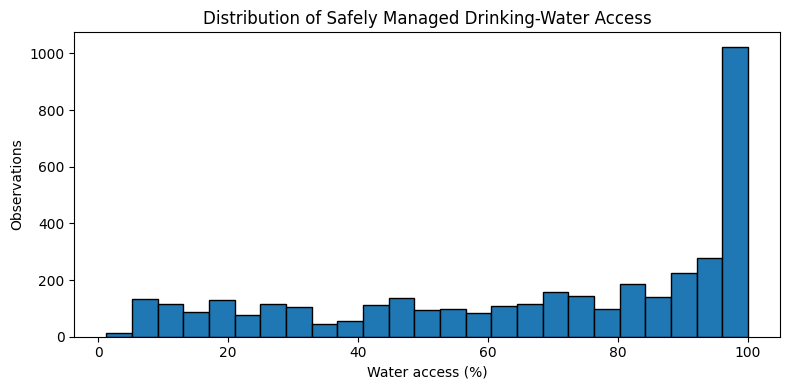

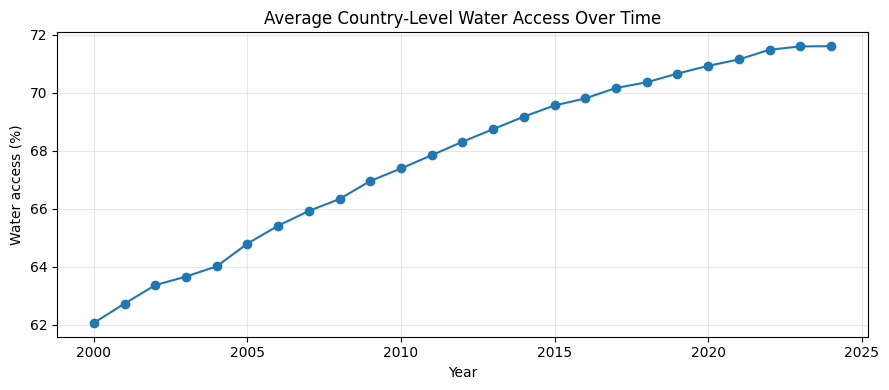

,Water_Access,Urban_Population,Unemployment
Water_Access,1.000,0.671,0.167
Urban_Population,0.671,1.000,0.088
Unemployment,0.167,0.088,1.000


In [4]:

# Water-access distribution
plt.figure(figsize=(8, 4))
plt.hist(data["Water_Access"], bins=25, edgecolor="black")
plt.xlabel("Water access (%)")
plt.ylabel("Observations")
plt.title("Distribution of Safely Managed Drinking-Water Access")
plt.tight_layout()
plt.show()

# Average water access by year
data.groupby("Year")["Water_Access"].mean().plot(
    figsize=(9, 4), marker="o"
)
plt.title("Average Country-Level Water Access Over Time")
plt.xlabel("Year")
plt.ylabel("Water access (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Correlation analysis
display(
    data[
        ["Water_Access", "Urban_Population", "Unemployment"]
    ].corr().round(3)
)


In [5]:

features = ["Water_Access", "Urban_Population", "Unemployment"]
window = 5

X, y, years, countries = [], [], [], []

data = data[data["Year"].between(2000, 2024)].copy()

for country, group in data.groupby("Country_Code"):
    group = group.sort_values("Year").dropna(
        subset=features
    ).reset_index(drop=True)

    values = group[features].to_numpy(dtype=np.float32)
    year_values = group["Year"].to_numpy()

    for i in range(window, len(group)):
        # Require consecutive historical years and a next-year target
        if not np.all(np.diff(year_values[i-window:i+1]) == 1):
            continue

        X.append(values[i-window:i])
        y.append(values[i, 0])
        years.append(year_values[i])
        countries.append(country)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
years = np.asarray(years, dtype=int)
countries = np.asarray(countries)

train = years <= 2018
valid = (years >= 2019) & (years <= 2020)
test = (years >= 2021) & (years <= 2024)

if not train.any() or not valid.any() or not test.any():
    raise ValueError(
        "A data split is empty. Check data coverage and missing values."
    )

print("Training:", train.sum())
print("Validation:", valid.sum())
print("Testing:", test.sum())

# Fit scalers using training data only
x_scaler = StandardScaler().fit(
    X[train].reshape(-1, len(features))
)
y_scaler = StandardScaler().fit(y[train].reshape(-1, 1))

def scale_X(values):
    return x_scaler.transform(
        values.reshape(-1, len(features))
    ).reshape(values.shape).astype(np.float32)

X_scaled = scale_X(X)
y_scaled = y_scaler.transform(y.reshape(-1, 1)).ravel().astype(np.float32)


Training: 1839
Validation: 266
Testing: 522


In [6]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class WaterTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Linear(3, 32)
        self.position = nn.Parameter(torch.randn(1, window, 32) * 0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=32,
            nhead=4,
            dim_feedforward=64,
            dropout=0.1,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=2
        )

        self.output = nn.Sequential(
            nn.LayerNorm(32),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = self.embedding(x) + self.position
        x = self.encoder(x)
        return self.output(x[:, -1]).squeeze(-1)


model = WaterTransformer().to(device)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_scaled[train], dtype=torch.float32),
        torch.tensor(y_scaled[train], dtype=torch.float32)
    ),
    batch_size=64,
    shuffle=True
)

X_val = torch.tensor(X_scaled[valid], dtype=torch.float32).to(device)
y_val = torch.tensor(y_scaled[valid], dtype=torch.float32).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=0.001, weight_decay=1e-4
)
loss_fn = nn.MSELoss()

best_loss = float("inf")
best_weights = None
patience = 0

for epoch in range(60):
    model.train()

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val), y_val).item()

    if val_loss < best_loss:
        best_loss = val_loss
        best_weights = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }
        patience = 0
    else:
        patience += 1

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}: validation loss = {val_loss:.4f}")

    if patience >= 10:
        break

model.load_state_dict(best_weights)
print("Transformer training completed.")


Device: cuda
Epoch 10: validation loss = 0.0023
Epoch 20: validation loss = 0.0016
Epoch 30: validation loss = 0.0015
Epoch 40: validation loss = 0.0007
Epoch 50: validation loss = 0.0002
Epoch 60: validation loss = 0.0008
Transformer training completed.


In [7]:

X_flat = X_scaled.reshape(len(X_scaled), -1)

linear = LinearRegression().fit(X_flat[train], y[train])

forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
).fit(X_flat[train], y[train])

model.eval()
with torch.no_grad():
    pred_scaled = model(
        torch.tensor(X_scaled[test], dtype=torch.float32).to(device)
    ).cpu().numpy()

pred_transformer = y_scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).ravel()

predictions = {
    "Linear Regression": linear.predict(X_flat[test]),
    "Random Forest": forest.predict(X_flat[test]),
    "Transformer": pred_transformer
}

results = pd.DataFrame([
    {
        "Model": name,
        "MAE": mean_absolute_error(y[test], pred),
        "RMSE": np.sqrt(mean_squared_error(y[test], pred)),
        "R2": r2_score(y[test], pred)
    }
    for name, pred in predictions.items()
])

display(results.round(3).sort_values("RMSE"))


,Model,MAE,RMSE,R2
0,Linear Regression,0.087,0.245,1.0
2,Transformer,0.365,0.512,1.0
1,Random Forest,0.401,0.637,1.0


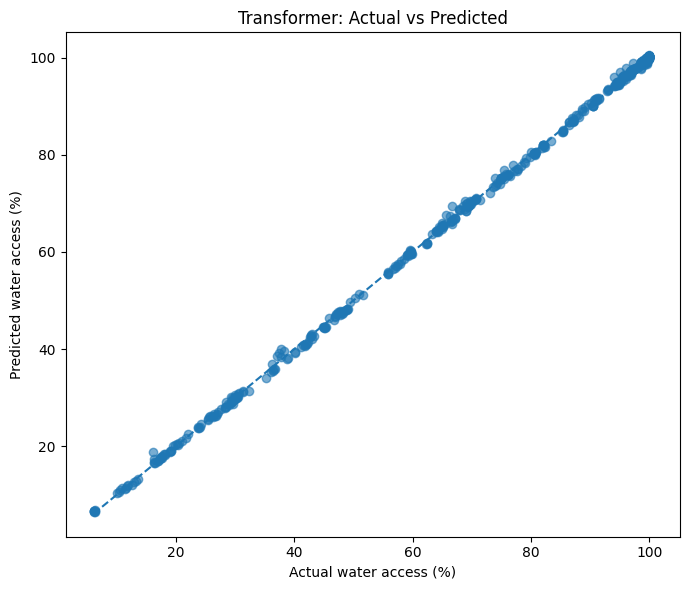

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

test_results = pd.DataFrame({
    "Country_Code": countries[test],
    "Year": years[test],
    "Actual": y[test],
    "Predicted": pred_transformer
})

plt.figure(figsize=(7, 6))
plt.scatter(test_results["Actual"], test_results["Predicted"], alpha=0.6)

low = min(test_results["Actual"].min(), test_results["Predicted"].min())
high = max(test_results["Actual"].max(), test_results["Predicted"].max())

plt.plot([low, high], [low, high], "--")
plt.xlabel("Actual water access (%)")
plt.ylabel("Predicted water access (%)")
plt.title("Transformer: Actual vs Predicted")
plt.tight_layout()
plt.show()

results.to_csv("model_comparison.csv", index=False)
test_results.to_csv("water_predictions.csv", index=False)

torch.save({
    "model_state_dict": model.state_dict(),
    "features": features,
    "window": window,
    "x_mean": x_scaler.mean_,
    "x_scale": x_scaler.scale_,
    "y_mean": y_scaler.mean_,
    "y_scale": y_scaler.scale_
}, "water_transformer.pt")

from google.colab import files
files.download("model_comparison.csv")
files.download("water_predictions.csv")
files.download("water_transformer.pt")
